In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

In [3]:
df=pd.read_csv("/content/solar_power_output.csv")
df.head()

,temperature,humidity,solar_irradiance,wind_speed,solar_power_output
0,19.363503,75.852937,266.619636,5.190818,128.101772
1,33.767858,62.887709,587.710853,4.791819,290.911789
2,28.299849,44.762209,885.651252,0.256421,442.336390
3,24.966462,85.103602,759.002398,3.412478,380.261988
4,13.900466,74.778494,825.905033,3.801956,415.931953


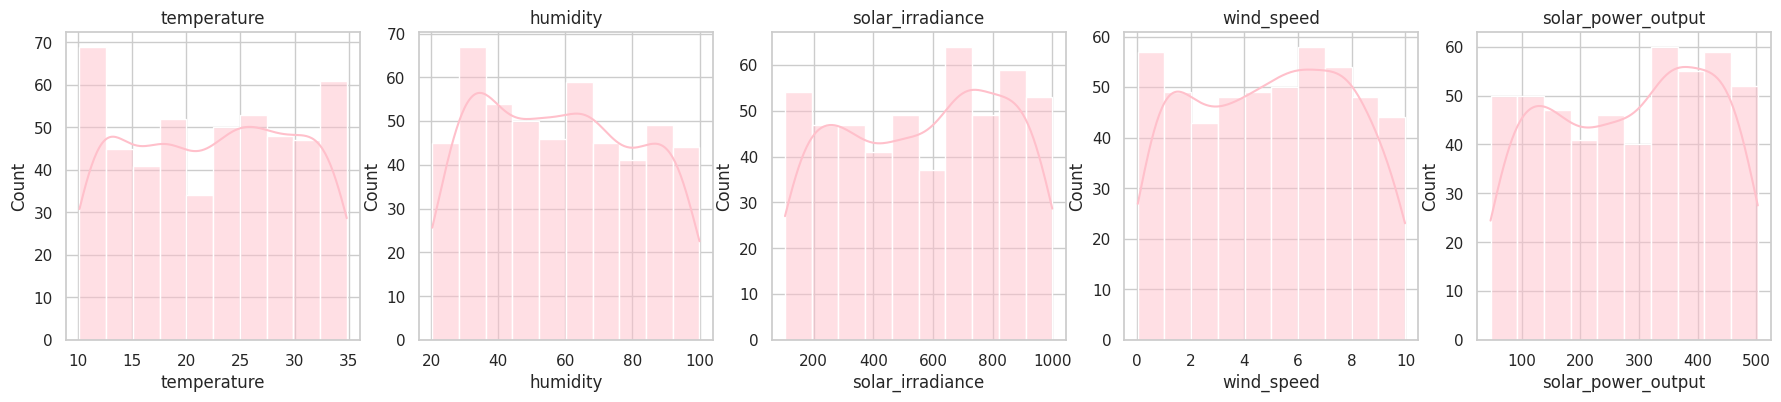

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(22,4))
for ax, col in zip(axes, df.columns):
  sns.histplot(df[col], kde=True, ax=ax, color="pink")
  ax.set_title(col)
plt.show()

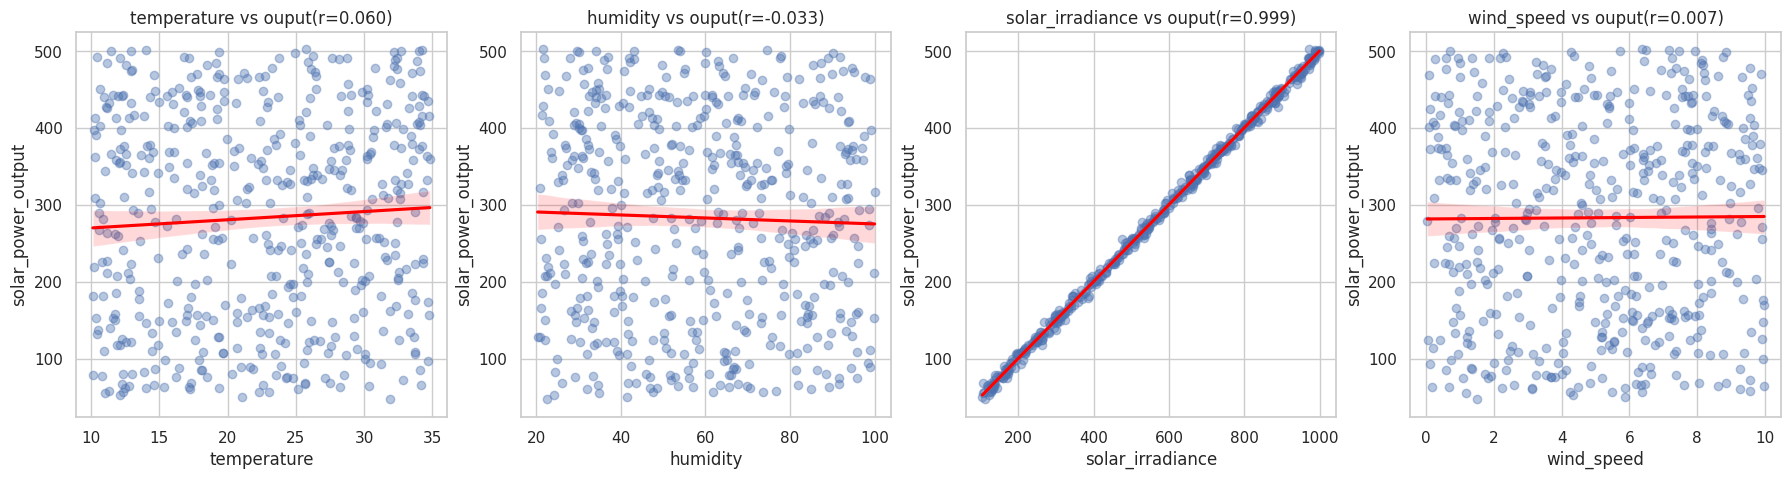

In [5]:
df["temperature"] = pd.to_numeric(df["temperature"], errors="coerce")

features =["temperature", "humidity","solar_irradiance","wind_speed"]
fig,axes=plt.subplots(1, 4, figsize=(22,5))
for ax,col in zip(axes, features):
  sns.regplot(x=df[col],y=df["solar_power_output"],ax=ax,scatter_kws={"alpha":0.4},line_kws={"color":"red"})
  r=df[col].corr(df["solar_power_output"])
  ax.set_title(f"{col} vs ouput(r={r:.3f})")
plt.show()

multivariant analysis


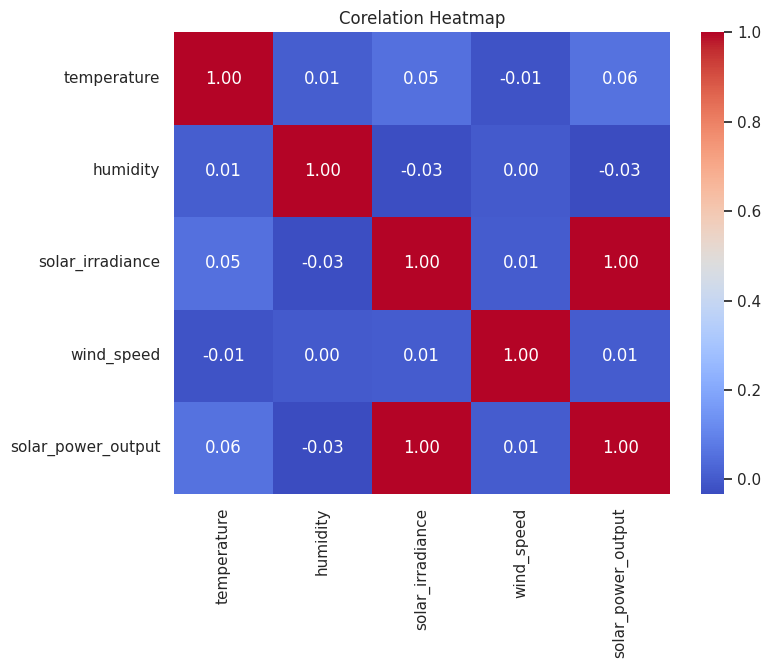

In [6]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Corelation Heatmap")
plt.show()


Data Preprocessing

In [7]:
df.isnull().sum()

,0
temperature,0
humidity,0
solar_irradiance,0
wind_speed,0
solar_power_output,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
x = df["solar_irradiance"]
y = df["solar_power_output"]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)


model training


In [10]:
model = LinearRegression()
# Reshape x_train to be 2D as expected by scikit-learn
model.fit(x_train.values.reshape(-1, 1), y_train)
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 0.5005361509109775
Intercept: 0.010596780972093711


final model evaluation on test data

In [11]:
y_pred=model.predict(x_test.values.reshape(-1, 1))
print("R2 :",r2_score(y_test,y_pred))
print("MAE :",mean_absolute_error(y_test,y_pred))
print("MSE :",mean_squared_error(y_test,y_pred))

R2 : 0.9981624336592926
MAE : 4.272564495023546
MSE : 32.33319189996614


graph of linear regression line

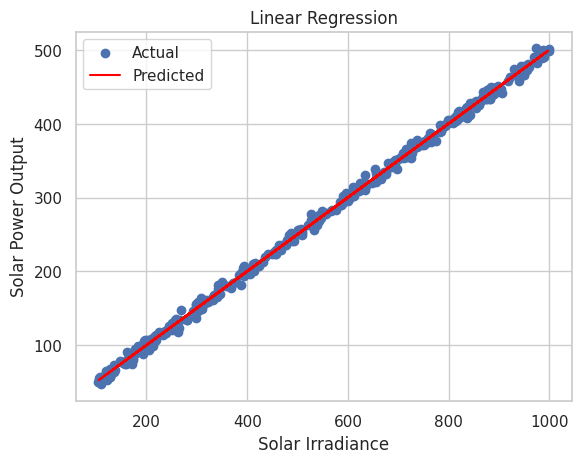

In [12]:
plt.scatter(x_train, y_train, label='Actual')
plt.plot(x_test, y_pred, color='red', label='Predicted')
plt.xlabel('Solar Irradiance')
plt.ylabel('Solar Power Output')
plt.title('Linear Regression')
plt.legend()
plt.show()

save model for deployment

In [13]:
joblib.dump(model, "model.pkl")
print("model saved")


model saved
